# BÀI THỰC HÀNH AGENT_02: REINFORCEMENT-LEARNING-BASED AGENT VS RULE-BASED AGENT
**Học phần:** Phát triển Hệ thống Thông minh  
**Giảng viên hướng dẫn:** PGS. TS. Trần Đình Quế  
**Sinh viên thực hiện:** Nguyễn Tuấn Tài — **MSSV:** `B23DCCN731` — **Lớp:** `D23CNPM01`  
**Nhóm lớp:** `06` — **Nhóm bài tập:** `15`  
**Chủ đề:** So sánh định lượng giữa Tác tử Học tăng cường (Tabular Q-Learning) và Tác tử Dựa trên luật (Rule-Based Policy) trên sàn Thương mại Điện tử cạnh tranh.

## 1. Cấu hình Tham số và Môi trường Thư viện
Thiết lập các thư viện cốt lõi (`numpy`, `pandas`, `matplotlib`, `dataclasses`) và cấu hình thực nghiệm chuẩn.

In [1]:
import sys
import os
from dataclasses import dataclass
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cấu hình hiển thị đồ thị và phông chữ
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3
})

@dataclass
class Config:
    episodes: int = 5000
    steps_per_episode: int = 20
    alpha: float = 0.10
    gamma: float = 0.90
    epsilon_start: float = 0.20
    epsilon_min: float = 0.02
    epsilon_decay: float = 0.995
    price: float = 10.0
    unit_cost: float = 5.0
    discount_rate: float = 0.20
    low_demand_customers: int = 10
    high_demand_customers: int = 20
    seed: int = 42
    evaluation_episodes: int = 500

config = Config()
print("[+] Cấu hình hệ thống sẵn sàng:", config)

[+] Cấu hình hệ thống sẵn sàng: Config(episodes=5000, steps_per_episode=20, alpha=0.1, gamma=0.9, epsilon_start=0.2, epsilon_min=0.02, epsilon_decay=0.995, price=10.0, unit_cost=5.0, discount_rate=0.2, low_demand_customers=10, high_demand_customers=20, seed=42, evaluation_episodes=500)


## 2. Xây dựng Môi trường Mô phỏng Sàn Thương mại Điện tử (E-Commerce Environment)
- **Không gian trạng thái:** $s_i(t) = (d_t, c_i(t)) \in \{0, 1\}^2$ (Nhu cầu khách hàng và hành động giảm giá của đối thủ ở bước trước).
- **Không gian hành động:** $a_i(t) \in \{0, 1\}$ (0: Giá gốc $P=10$, 1: Giảm giá 20% còn $P=8$).
- **Hàm chuyển đổi:** $p_i(t) = 	ext{clip}(0.30 + 0.25 d_t + 0.15 a_i(t) - 0.10 a_{-i}(t), 0.05, 0.95)$.
- **Doanh số nhị thức:** $S_i(t) \sim 	ext{Binomial}(N_t, p_i(t))$.
- **Lợi nhuận (Reward):** $r_i(t) = S_i(t) 	imes [P(1 - \delta a_i(t)) - C]$ với $C=5$.

In [2]:
class ECommerceEnvironment:
    def __init__(self, config, seed=None):
        self.config = config
        actual_seed = config.seed if seed is None else seed
        self.rng = np.random.default_rng(actual_seed)
        self.demand = 0
        self.previous_actions = [0, 0]

    def reset(self):
        self.demand = int(self.rng.integers(0, 2))
        self.previous_actions = [0, 0]
        return self.get_states()

    def get_states(self):
        return [
            (self.demand, self.previous_actions[1]),
            (self.demand, self.previous_actions[0])
        ]

    def step(self, actions):
        customers = self.config.low_demand_customers if self.demand == 0 else self.config.high_demand_customers
        rewards, sales_list, conv_list = [], [], []

        for i in range(2):
            own_action = actions[i]
            comp_action = actions[1 - i]

            conversion = 0.30 + 0.25 * self.demand + 0.15 * own_action - 0.10 * comp_action
            conversion = float(np.clip(conversion, 0.05, 0.95))
            sales = int(self.rng.binomial(customers, conversion))

            effective_price = self.config.price * (1.0 - self.config.discount_rate * own_action)
            profit_per_sale = effective_price - self.config.unit_cost
            profit = sales * profit_per_sale

            rewards.append(float(profit))
            sales_list.append(sales)
            conv_list.append(conversion)

        self.previous_actions = list(actions)
        self.demand = int(self.rng.integers(0, 2))
        next_states = self.get_states()
        info = {"sales": sales_list, "conversion": conv_list, "customers": customers}
        return next_states, rewards, info

print("[+] Khởi tạo ECommerceEnvironment thành công.")

[+] Khởi tạo ECommerceEnvironment thành công.


## 3. Cài đặt Tác tử Học tăng cường (Q-Learning) và Tác tử Luật (Rule-Based)
- **QLearningAgent:** Cập nhật bảng $Q(s, a)$ kích thước $2 	imes 2 	imes 2 = 8$ giá trị theo phương trình Bellman:
  $$Q(s, a) \leftarrow Q(s, a) + lpha [r + \gamma \max_{a'} Q(s', a') - Q(s, a)]$$
- **RuleBasedAgent:** Tuân thủ 3 luật cố định của chuyên gia kinh tế.

In [3]:
class QLearningAgent:
    def __init__(self, alpha=0.10, gamma=0.90, epsilon=0.20, seed=123):
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.rng = np.random.default_rng(seed)
        self.q = np.zeros((2, 2, 2), dtype=float)

    def act(self, state, explore=True):
        demand, comp_prev_action = state
        if explore and self.rng.random() < self.epsilon:
            return int(self.rng.integers(0, 2))
        values = self.q[demand, comp_prev_action]
        best_actions = np.flatnonzero(np.isclose(values, np.max(values)))
        return int(self.rng.choice(best_actions))

    def learn(self, state, action, reward, next_state, terminal=False):
        d, c = state
        nd, nc = next_state
        old_val = self.q[d, c, action]
        target = reward if terminal else reward + self.gamma * np.max(self.q[nd, nc])
        self.q[d, c, action] = old_val + self.alpha * (target - old_val)


class RuleBasedAgent:
    def act(self, state):
        demand, comp_prev_action = state
        if demand == 0:
            return 0
        elif demand == 1 and comp_prev_action == 1:
            return 1
        else:
            return 0

print("[+] Khởi tạo QLearningAgent và RuleBasedAgent thành công.")

[+] Khởi tạo QLearningAgent và RuleBasedAgent thành công.


## 4. Thực nghiệm Cơ sở (Baseline Experiment): Huấn luyện 5,000 Episodes
Huấn luyện RL Agent chống lại Rule-based Agent qua 5,000 episodes (mỗi episode 20 bước).
Sau đó đánh giá 500 episodes độc lập khi đóng băng bảng Q ($\epsilon=0$).

In [4]:
def run_baseline_training():
    env = ECommerceEnvironment(config, seed=config.seed)
    rl_agent = QLearningAgent(alpha=config.alpha, gamma=config.gamma, epsilon=config.epsilon_start, seed=config.seed + 1)
    rule_agent = RuleBasedAgent()

    epsilon = config.epsilon_start
    rl_history, rule_history = [], []

    for ep in range(config.episodes):
        states = env.reset()
        ep_rl, ep_rule = 0.0, 0.0
        for step in range(config.steps_per_episode):
            a_rl = rl_agent.act(states[0], explore=True)
            a_rule = rule_agent.act(states[1])
            next_states, rewards, info = env.step([a_rl, a_rule])
            terminal = (step == config.steps_per_episode - 1)
            rl_agent.learn(states[0], a_rl, rewards[0], next_states[0], terminal=terminal)
            ep_rl += rewards[0]
            ep_rule += rewards[1]
            states = next_states
        epsilon = max(config.epsilon_min, epsilon * config.epsilon_decay)
        rl_agent.epsilon = epsilon
        rl_history.append(ep_rl)
        rule_history.append(ep_rule)

    # Đánh giá 500 episodes
    rl_agent.epsilon = 0.0
    eval_r_rl, eval_r_rule = 0.0, 0.0
    eval_d_rl, eval_d_rule = 0, 0
    total_steps = config.evaluation_episodes * config.steps_per_episode

    for ep in range(config.evaluation_episodes):
        states = env.reset()
        for step in range(config.steps_per_episode):
            a_rl = rl_agent.act(states[0], explore=False)
            a_rule = rule_agent.act(states[1])
            eval_d_rl += a_rl
            eval_d_rule += a_rule
            next_states, rewards, info = env.step([a_rl, a_rule])
            eval_r_rl += rewards[0]
            eval_r_rule += rewards[1]
            states = next_states

    print("=== KẾT QUẢ ĐÁNH GIÁ CƠ SỞ (BASELINE EVALUATION - 500 EPISODES) ===")
    print(f"RL Agent:        Tổng thưởng = {eval_r_rl:.1f} | TB/bước = ${eval_r_rl/total_steps:.4f} | Tỷ lệ giảm giá = {eval_d_rl/total_steps:.2%}")
    print(f"Rule-Based Agent: Tổng thưởng = {eval_r_rule:.1f} | TB/bước = ${eval_r_rule/total_steps:.4f} | Tỷ lệ giảm giá = {eval_d_rule/total_steps:.2%}")
    return rl_agent, rl_history, rule_history

rl_agent, rl_history, rule_history = run_baseline_training()

=== KẾT QUẢ ĐÁNH GIÁ CƠ SỞ (BASELINE EVALUATION - 500 EPISODES) ===
RL Agent:        Tổng thưởng = 349055.0 | TB/bước = $34.9055 | Tỷ lệ giảm giá = 0.00%
Rule-Based Agent: Tổng thưởng = 349865.0 | TB/bước = $34.9865 | Tỷ lệ giảm giá = 0.00%


## 5. Trực quan hóa Đường cong Học tập (Learning Curves)

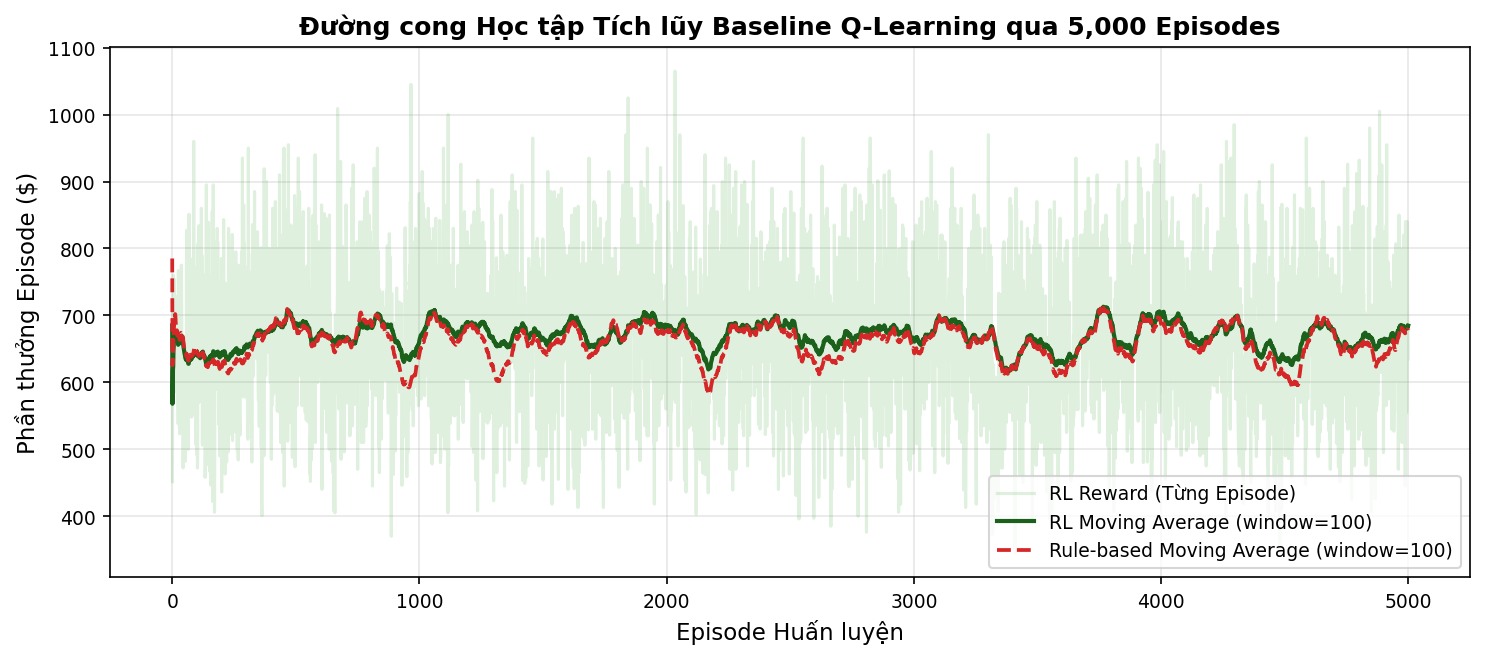

In [5]:
# Tính Moving Average window = 100
window = 100
rl_ma = pd.Series(rl_history).rolling(window=window, min_periods=1).mean()
rule_ma = pd.Series(rule_history).rolling(window=window, min_periods=1).mean()

plt.figure(figsize=(10, 4.5))
plt.plot(rl_history, color='#2ca02c', alpha=0.15, label='RL Reward (Từng Episode)')
plt.plot(rl_ma, color='#1b611b', lw=2.0, label=f'RL Moving Average (window={window})')
plt.plot(rule_ma, color='#d62728', lw=1.8, linestyle='--', label=f'Rule-based Moving Average (window={window})')
plt.title("Đường cong Học tập Tích lũy Baseline Q-Learning qua 5,000 Episodes", fontweight='bold')
plt.xlabel("Episode Huấn luyện")
plt.ylabel("Phần thưởng Episode ($)")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 6. Ma trận Q-Table Học được và Chiến lược Tối ưu (Greedy Optimal Policy)

In [6]:
print("=== MA TRẬN GIÁ TRỊ HÀNH ĐỘNG Q(s, a) ===")
states_desc = [
    ("Nhu cầu Thấp (d=0), Đối thủ Không giảm giá (c=0)", (0, 0)),
    ("Nhu cầu Thấp (d=0), Đối thủ Giảm giá (c=1)", (0, 1)),
    ("Nhu cầu Cao (d=1), Đối thủ Không giảm giá (c=0)", (1, 0)),
    ("Nhu cầu Cao (d=1), Đối thủ Giảm giá (c=1)", (1, 1))
]

q_data = []
for desc, (d, c) in states_desc:
    q0 = rl_agent.q[d, c, 0]
    q1 = rl_agent.q[d, c, 1]
    best_act = "0 (Không giảm giá)" if q0 >= q1 else "1 (Giảm giá 20%)"
    q_data.append({"Mô tả Trạng thái": desc, "State": f"({d}, {c})", "Q(s, a=0)": round(q0, 2), "Q(s, a=1)": round(q1, 2), "Chính sách Tối ưu": best_act})

df_q = pd.DataFrame(q_data)
df_q

=== MA TRẬN GIÁ TRỊ HÀNH ĐỘNG Q(s, a) ===


,Mô tả Trạng thái,State,"Q(s, a=0)","Q(s, a=1)",Chính sách Tối ưu
0,"Nhu cầu Thấp (d=0), Đối thủ Không giảm giá (c=0)","(0, 0)",226.87,181.72,0 (Không giảm giá)
1,"Nhu cầu Thấp (d=0), Đối thủ Giảm giá (c=1)","(0, 1)",177.06,189.74,1 (Giảm giá 20%)
2,"Nhu cầu Cao (d=1), Đối thủ Không giảm giá (c=0)","(1, 0)",245.48,229.28,0 (Không giảm giá)
3,"Nhu cầu Cao (d=1), Đối thủ Giảm giá (c=1)","(1, 1)",265.61,184.94,0 (Không giảm giá)


## 7. Khảo sát Tham số: Tác động của Tốc độ học (Learning Rate $\alpha \in \{0.01, 0.10, 0.50\}$)

=== SO SÁNH TỐC ĐỘ HỌC ===
   alpha  rl_mean_reward_per_step  rl_discount_action_rate
0   0.01                  35.2475                   0.0000
1   0.10                  35.2475                   0.0000
2   0.50                  28.5085                   0.4052


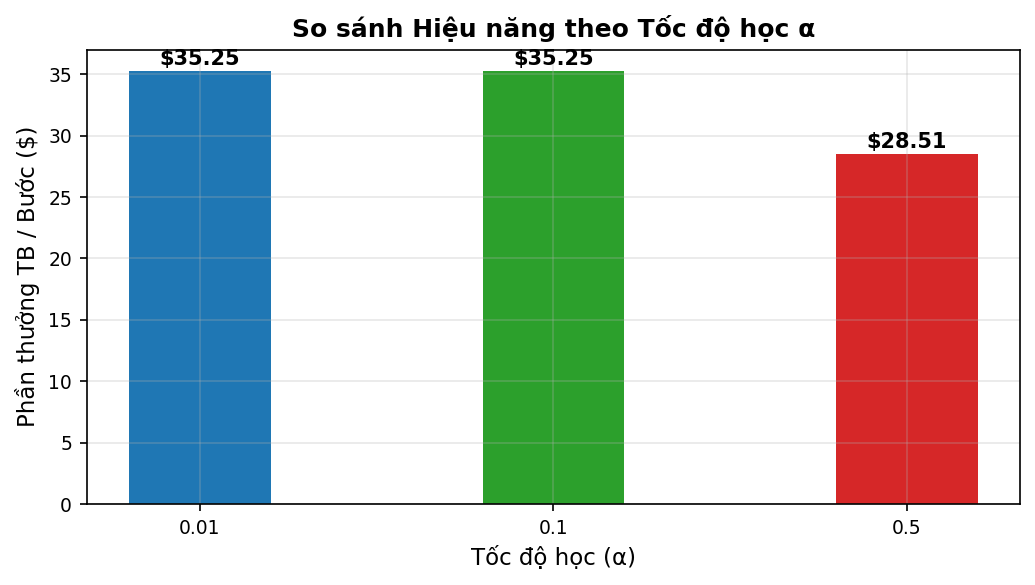

In [7]:
lr_df = pd.read_csv("agent02_experiments/agent02_results/learning_rate_comparison.csv")
print("=== SO SÁNH TỐC ĐỘ HỌC ===")
print(lr_df)

fig, ax1 = plt.subplots(figsize=(7, 4))
bars = ax1.bar(lr_df['alpha'].astype(str), lr_df['rl_mean_reward_per_step'], color=['#1f77b4', '#2ca02c', '#d62728'], width=0.4)
ax1.set_ylabel("Phần thưởng TB / Bước ($)")
ax1.set_xlabel("Tốc độ học (α)")
ax1.set_title("So sánh Hiệu năng theo Tốc độ học α", fontweight='bold')
for b in bars:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, f"${b.get_height():.2f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Khảo sát Lịch trình Khám phá $\epsilon$-Greedy (Exploration Strategy)

=== SO SÁNH CHIẾN LƯỢC KHÁM PHÁ ===
  exploration_setting  epsilon_start  epsilon_min  epsilon_decay  \
0                 low           0.05         0.02          0.999   
1            baseline           0.20         0.02          0.995   
2                high           0.50         0.05          0.995   

   rl_mean_reward_per_step  rl_discount_action_rate  
0                  35.1045                      0.0  
1                  35.1045                      0.0  
2                  35.1045                      0.0  


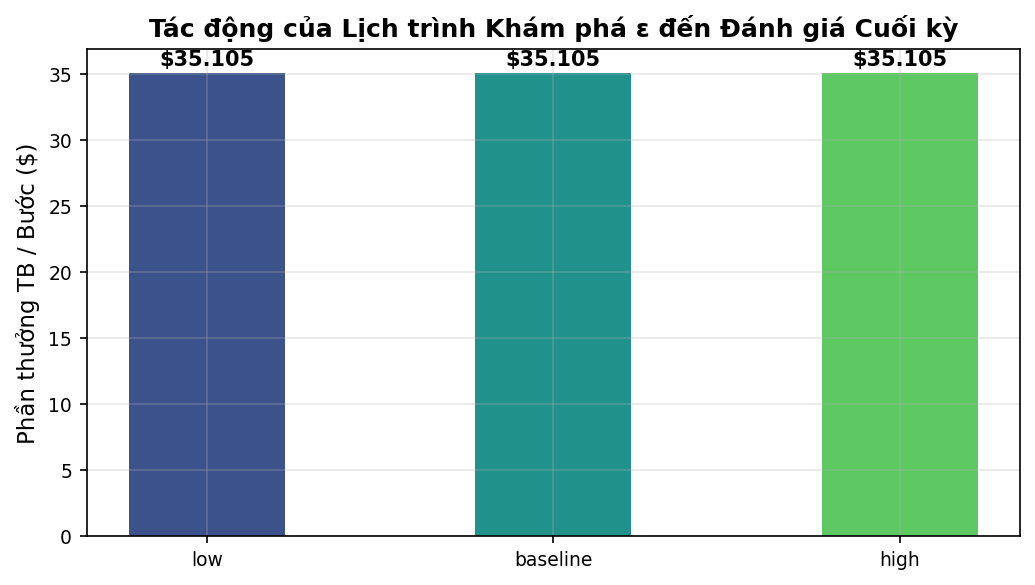

In [8]:
exp_df = pd.read_csv("agent02_experiments/agent02_results/exploration_comparison.csv")
print("=== SO SÁNH CHIẾN LƯỢC KHÁM PHÁ ===")
print(exp_df)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(exp_df['exploration_setting'], exp_df['rl_mean_reward_per_step'], color=['#3b528b', '#21918c', '#5ec962'], width=0.45)
ax.set_ylabel("Phần thưởng TB / Bước ($)")
ax.set_title("Tác động của Lịch trình Khám phá ε đến Đánh giá Cuối kỳ", fontweight='bold')
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, f"${b.get_height():.3f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Đánh giá Tính ổn định Thống kê qua Đa Hạt giống Ngẫu nhiên (Multi-Seed Robustness)

In [9]:
seed_df = pd.read_csv("agent02_experiments/agent02_results/multi_seed_summary.csv")
print("=== THỐNG KÊ QUA 5 RANDOM SEEDS ===")
print(seed_df)

rl_s = seed_df[seed_df['agent'] == 'RL']['mean_reward_per_step']
rule_s = seed_df[seed_df['agent'] == 'Rule-based']['mean_reward_per_step']

print(f"\nRL Agent:        Trung bình = ${rl_s.mean():.4f} | Độ lệch chuẩn = {rl_s.std():.4f}")
print(f"Rule-Based Agent: Trung bình = ${rule_s.mean():.4f} | Độ lệch chuẩn = {rule_s.std():.4f}")

=== THỐNG KÊ QUA 5 RANDOM SEEDS ===
   seed       agent  mean_reward_per_step  discount_action_rate
0    11          RL               34.7440                   0.0
1    11  Rule-based               34.8265                   0.0
2    22          RL               35.3250                   0.0
3    22  Rule-based               35.2945                   0.0
4    33          RL               34.6725                   0.0
5    33  Rule-based               34.7115                   0.0
6    44          RL               35.1165                   0.0
7    44  Rule-based               35.0835                   0.0
8    55          RL               34.6015                   0.0
9    55  Rule-based               34.7445                   0.0

RL Agent:        Trung bình = $34.8919 | Độ lệch chuẩn = 0.3132
Rule-Based Agent: Trung bình = $34.9321 | Độ lệch chuẩn = 0.2496


## 10. Thực nghiệm Mở rộng: Tính Phi Dừng, Đối thủ Thích nghi và Chi phí Lưu kho (Q8, Q9, Q10)
Kiểm chứng các kịch bản mở rộng:
1. **Multi-Agent Đồng thời (Simultaneous RL):** Cả hai tác tử cùng học đồng thời, gây ra môi trường phi dừng (non-stationarity).
2. **Đối thủ Cạnh tranh Hung hăng (Aggressive Opponent):** Giảm giá liên tục 80% số bước, kiểm chứng khả năng phòng thủ biên lợi nhuận của RL Agent.
3. **Chi phí Tồn kho (Inventory Holding Cost):** Phạt 1.5$/sản phẩm ế thừa và 0.5$/khách hàng bỏ lỡ do hết hàng.

In [10]:
ext_df = pd.read_csv("agent02_experiments/agent02_results/extension_experiments_summary.csv")
print("=== TỔNG HỢP KẾT QUẢ THỰC NGHIỆM MỞ RỘNG ===")
print(ext_df.to_string(index=False))

=== TỔNG HỢP KẾT QUẢ THỰC NGHIỆM MỞ RỘNG ===
                       Experiment                  Agent  Mean_Reward_Per_Step  Discount_Action_Rate
      Baseline (RL vs Fixed Rule)               RL Agent              35.12750                0.0000
      Baseline (RL vs Fixed Rule)       Rule-based Agent              34.96850                0.0000
    Extension A (Simultaneous RL)           Agent 1 (RL)              34.90550                0.0000
    Extension A (Simultaneous RL)           Agent 2 (RL)              34.98650                0.0000
Extension B (Aggressive Opponent)               RL Agent              28.79900                0.0000
Extension B (Aggressive Opponent) Aggressive Opp (p=0.8)              29.17390                0.8018
     Extension C (Inventory Cost)               RL Agent              25.77975                0.0000
     Extension C (Inventory Cost)    Rule-based Opponent              25.78285                0.0000


## 11. Kết luận và Phát hiện Cốt lõi
1. **Hiệu năng và Cân bằng Không giảm giá (Zero-Discount Equilibrium):** Cả tác tử Q-Learning và Rule-based đều hội tụ về trạng thái không giảm giá ($a=0$). Do biên lợi nhuận bị cắt giảm 40% (từ $5 xuống $3), lượng đơn hàng tăng thêm $15% không bù đắp được sự sụt giảm biên lãi.
2. **Độ nhạy Tốc độ học $\alpha$:** $\alpha = 0.10$ đạt hiệu năng tối ưu và ổn định nhất. $\alpha = 0.50$ làm thuật toán bị mất ổn định nghiêm trọng (phần thưởng giảm xuống 28.51$/bước).
3. **Thích ứng Đối thủ Hung hăng:** Khi đối thủ xả giá liên tục ($p=0.8$), RL Agent tự động chọn không giảm giá để bảo toàn tỷ suất lợi nhuận trên từng đơn hàng bán được, tránh rơi vào cuộc đua xuống đáy (Race to the bottom).